# Linear probes: what do frozen features know?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/2_models/01_linear_probes.ipynb) &nbsp; Guide note: [guide-representation-learning](https://www.matthewwnuk.com/guide-representation-learning.html#probing)

A representation is useful if simple things can be read from it with little data. The standard test is a
linear probe: freeze the encoder, train one linear layer on its features, and measure accuracy.

The data is 1,516 frames from 379 robot demonstrations, each with a CLIP image embedding computed in
advance. The baseline is the frame itself shrunk to 16 x 16 grey pixels. A probe without a baseline
shows very little.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from guide_utils import data, style
style.use()
f = data.libero_frames(); d = data.libero(); tasks = data.libero_tasks()
clip, pix, ep, task, frac = f["clip"], f["pixels"], f["episode"], f["task"], f["frac"]
pix = (pix - pix.mean(0)) / (pix.std(0) + 1e-6)
print(clip.shape, pix.shape, "episodes:", len(np.unique(ep)))

(1516, 512) (1516, 256) episodes: 379


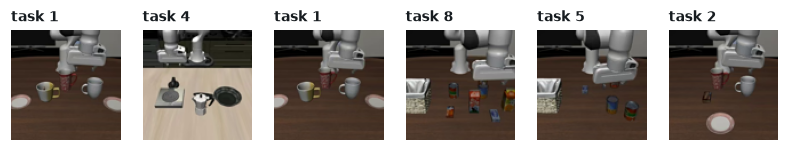

task 1: put the white mug on the left plate and put the yellow and white mug on the right plate


In [3]:
fig, ax = plt.subplots(1, 6, figsize=(9, 1.8))
for a, i in zip(ax, [0, 200, 420, 700, 1000, 1300]): a.imshow(f["thumbs"][i]); a.set_title(f"task {task[i] + 1}", fontsize=9); style.bare(a)
plt.show(); print("task 1:", tasks[0])

## Three questions to ask of the features

1. Which of the ten tasks is this frame from?
2. How far through the episode is it? Each frame was taken at one of four stages.
3. Is the gripper closed? That comes from the robot's recorded state, which the image encoder never saw.

In [4]:
stage = np.searchsorted([0.2, 0.5, 0.7], frac)
closed = []
for e, fr in zip(ep, frac):
    s = d["state"][d["episode"] == e]; i = min(int(fr * len(s)), len(s) - 1); closed.append(int(s[i, 6] - s[i, 7] < 0.04))   # distance between the two fingers
closed = np.array(closed); print(f"gripper closed in {closed.mean():.0%} of frames")

gripper closed in 31% of frames


## The probe

Whole episodes are held out, never single frames: frames from one episode are near-copies of each other,
and splitting them across training and test would measure memory.

which task?      frozen CLIP features   ['78%', '83%', '90%', '93%', '95%', '97%']


which task?      raw pixels             ['69%', '75%', '84%', '88%', '92%', '96%']


which stage?     frozen CLIP features   ['27%', '29%', '34%', '40%', '49%', '62%']


which stage?     raw pixels             ['30%', '31%', '41%', '47%', '54%', '63%']
gripper closed?  frozen CLIP features   ['57%', '60%', '64%', '64%', '68%', '72%']
gripper closed?  raw pixels             ['57%', '57%', '65%', '62%', '67%', '69%']


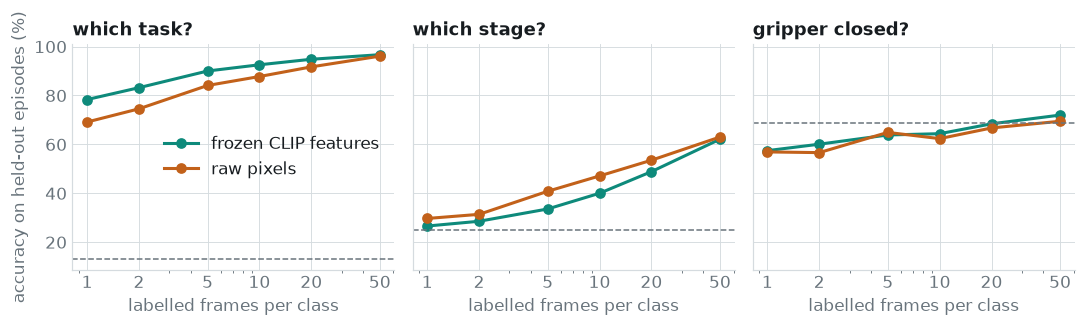

In [5]:
def probe(X, y, k, seed):
    """Train on k labelled frames per class from half the episodes; test on every frame of the other half."""
    rng = np.random.default_rng(seed); eps = rng.permutation(np.unique(ep)); train_ep = np.isin(ep, eps[: len(eps) // 2]); idx = []
    for c in np.unique(y):
        cand = np.flatnonzero(train_ep & (y == c)); idx += list(rng.choice(cand, min(k, len(cand)), replace=False))
    return LogisticRegression(max_iter=2000, C=10).fit(X[idx], y[idx]).score(X[~train_ep], y[~train_ep])

ks = [1, 2, 5, 10, 20, 50]; fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for a, (name, y) in zip(ax, (("which task?", task), ("which stage?", stage), ("gripper closed?", closed))):
    for label, X in (("frozen CLIP features", clip), ("raw pixels", pix)):
        acc = [np.mean([probe(X, y, k, s) for s in range(6)]) * 100 for k in ks]; a.plot(ks, acc, marker="o", label=label)
        print(f"{name:16s} {label:22s}", [f"{v:.0f}%" for v in acc])
    chance = max(np.bincount(y)) / len(y) * 100; a.axhline(chance, color=style.MUTED, ls="--", lw=1); a.set_xscale("log"); a.set_xticks(ks); a.set_xticklabels(ks); a.set_title(name); a.set_xlabel("labelled frames per class")
ax[0].set_ylabel("accuracy on held-out episodes (%)"); ax[0].legend(); plt.tight_layout(); plt.show()

Three things to read from this.

- With a single labelled frame per task, frozen features already identify the task most of the time.
  That is what pretraining buys: the work was done before any labels arrived.
- The pixel baseline is not far behind on that question, because these scenes look very different from
  one another. A high probe score on an easy question says little about the encoder.
- On the questions the encoder was never trained for, the gap is smaller. "Good features" is always
  relative to a question.

## Things to try

- Split by frame, not by episode (`train_ep = rng.random(len(ep)) < 0.5`). How much does accuracy rise, and why is that misleading?
- Probe for the hand's height (`d["state"][:, 2]`) with `Ridge` regression.
- Reduce the CLIP features to their first 16 principal components. How much is lost?